In [114]:
using Revise
includet("IsingLib.jl")
using .IsingLib

In [115]:
N = 16

function anti_aligned_lattice(N)
    base = [1 -1; -1 1]
    if N % 2 == 0
        return repeat(base, div(N, 2), div(N, 2))
    else
        return repeat(base, div(N+1, 2), div(N+1, 2))[1:N, 1:N]
    end
end

lattice_unif = ones(N, N)
lattice_rand = rand((1, -1) ,N, N)
lattice_anti = anti_aligned_lattice(N)

16×16 Matrix{Int64}:
  1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1
 -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1
  1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1
 -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1
  1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1
 -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1
  1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1
 -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1
  1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1
 -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1
  1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1
 -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1
  1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1
 -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1
  1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1   1  -1
 -1   1  -1   1  -1

In [116]:
mcs = 200
T = 3.03

spins_unif, energy_unif = metropolis_spins_energy(lattice_unif, mcs, T, get_energy(lattice_unif))
spins_rand, energy_rand = metropolis_spins_energy(lattice_rand, mcs, T, get_energy(lattice_rand))
spins_anti, energy_anti = metropolis_spins_energy(lattice_anti, mcs, T, get_energy(lattice_anti))

([4.0, -30.0, -16.0, -24.0, -2.0, 44.0, 44.0, 44.0, 56.0, 64.0  …  16.0, 22.0, 28.0, 48.0, 56.0, 32.0, 72.0, 52.0, 48.0, 14.0], [-100.0, -156.0, -168.0, -180.0, -180.0, -200.0, -180.0, -164.0, -192.0, -248.0  …  -204.0, -208.0, -248.0, -172.0, -144.0, -136.0, -180.0, -216.0, -240.0, -212.0])

Podemos estimar el **equilibration time** $\tau_{eq}$, es decir, el tiempo que tarda la cadena de Markov de Metropolis en converger a la distribución, viendo en que momento las curvas de energía y magnetización se cruzan y empiezan a comportarse similarmente para distintas configuraciones iniciales.

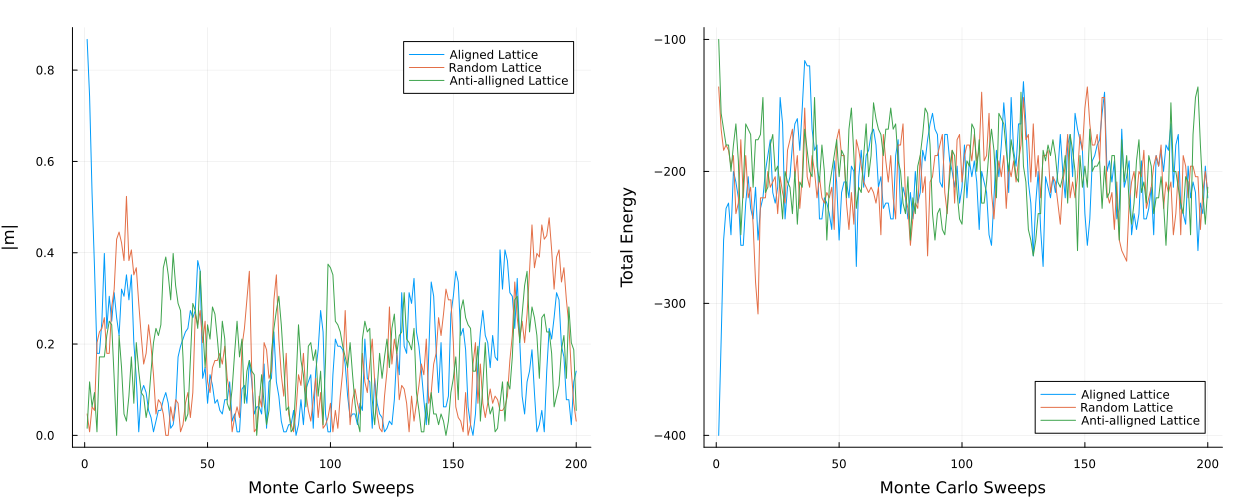

In [120]:
using Plots
using Plots.PlotMeasures

p1 = plot(abs.(spins_unif ./ N^2),  xlabel="Monte Carlo Sweeps", ylabel="|m|", label= "Aligned Lattice")
plot!(p1, abs.(spins_rand ./ N^2), label="Random Lattice")
plot!(p1, abs.(spins_anti ./ N^2), label="Anti-alligned Lattice")
p2 = plot(energy_unif, xlabel="Monte Carlo Sweeps", ylabel="Total Energy", label="Aligned Lattice")
plot!(p2, energy_rand, label="Random Lattice")
plot!(p2, energy_anti, label="Anti-alligned Lattice")

p = plot(p1, p2, layout=(1, 2), size=(1250, 500), margin=5mm)

En este caso observamos que a partir de $t=25$ la cadena parece estabilizarse al rededor de una distribución estacionaria. Por lo que si elegimos un burn-in $b=100$ ya debería ser suficiente para que $b\ge \tau_{eq}$

In [121]:
savefig(p, "simulation_results/equilibration_figure.png")

"c:\\Users\\Pablo\\Documents\\ipre-bacterias\\simulation_results\\equilibration_figure.png"